Hypothese 2: Ein ML-Modell mit hoher Accuracy muss nicht unbedingt gute Unsicherheitsschätzungen liefern

--> 1. Accuracy berechnen: Anteil der richtigen Vorhersagen
--> 2. Unsicherheit berechnen mit Predictive Entropy
--> 3. Error Detection: Man prüft, ob das Modell anhand seiner Unsicherheit erkennen kann, wann seine eigene Vorhersage wahrscheinlich falsch ist

In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from probly.quantification import entropy

# Probly: Unsicherheit quantifizieren
from probly.representation.distribution import create_categorical_distribution

In [41]:
SEED = 42

X, y = make_moons(n_samples=600, noise=0.25, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 420
Test samples: 180


In [42]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "Neural Network": make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(20, 20), max_iter=1000, random_state=SEED)
    ),
}

Accuracy berechnen

In [43]:
accuracy_results = []
trained_models = {}

for name, model in models.items():
    clf = clone(model)

    # Modell trainieren
    clf.fit(X_train, y_train)

    # Klassen vorhersagen
    predictions = clf.predict(X_test)

    # Accuracy berechnen
    accuracy = accuracy_score(y_test, predictions)

    # Modell speichern
    trained_models[name] = clf

    accuracy_results.append({"Model": name, "Accuracy": accuracy})

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df.sort_values("Accuracy", ascending=False))

,Model,Accuracy
3,Neural Network,0.944444
2,Random Forest,0.933333
1,Decision Tree,0.911111
0,Logistic Regression,0.844444


Unsicherheit mit Predictive Entropy berechnen

In [44]:
uncertainty_results = []
uncertainty_values = {}

for name, clf in trained_models.items():
    # Wahrscheinlichkeiten für beide Klassen
    probabilities = clf.predict_proba(X_test)

    # Probly: Wahrscheinlichkeitsverteilung erstellen
    distribution = create_categorical_distribution(probabilities)

    # Probly: Predictive Entropy berechnen
    uncertainty = np.asarray(entropy(distribution))

    # Unsicherheitswerte speichern
    uncertainty_values[name] = uncertainty

    uncertainty_results.append(
        {
            "Model": name,
            "Mean Entropy": uncertainty.mean(),
            "Min Entropy": uncertainty.min(),
            "Max Entropy": uncertainty.max(),
        }
    )

uncertainty_df = pd.DataFrame(uncertainty_results)

display(uncertainty_df)

,Model,Mean Entropy,Min Entropy,Max Entropy
0,Logistic Regression,0.310562,0.013952,0.693147
1,Decision Tree,0.121824,0.000000,0.636514
2,Random Forest,0.200092,0.000000,0.693147
3,Neural Network,0.220993,0.000356,0.693141


Error Detection:

In [45]:
evaluation_results = []

for name, clf in trained_models.items():
    predictions = clf.predict(X_test)

    # Unsicherheit aus Probly
    uncertainty = uncertainty_values[name]

    # 1 = falsche Vorhersage, 0 = richtige Vorhersage
    errors = (predictions != y_test).astype(int)

    # Error Detection AUROC
    if len(np.unique(errors)) == 2:
        error_auc = roc_auc_score(errors, uncertainty)
    else:
        error_auc = np.nan

    evaluation_results.append({"Model": name, "Error Detection AUROC": error_auc})

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

,Model,Error Detection AUROC
0,Logistic Regression,0.849389
1,Decision Tree,0.601944
2,Random Forest,0.783730
3,Neural Network,0.852353


In [46]:
results_df = accuracy_df.merge(uncertainty_df, on="Model").merge(evaluation_df, on="Model")

display(results_df.sort_values("Accuracy", ascending=False).round(3))

,Model,Accuracy,Mean Entropy,Min Entropy,Max Entropy,Error Detection AUROC
3,Neural Network,0.944,0.221,0.000,0.693,0.852
2,Random Forest,0.933,0.200,0.000,0.693,0.784
1,Decision Tree,0.911,0.122,0.000,0.637,0.602
0,Logistic Regression,0.844,0.311,0.014,0.693,0.849


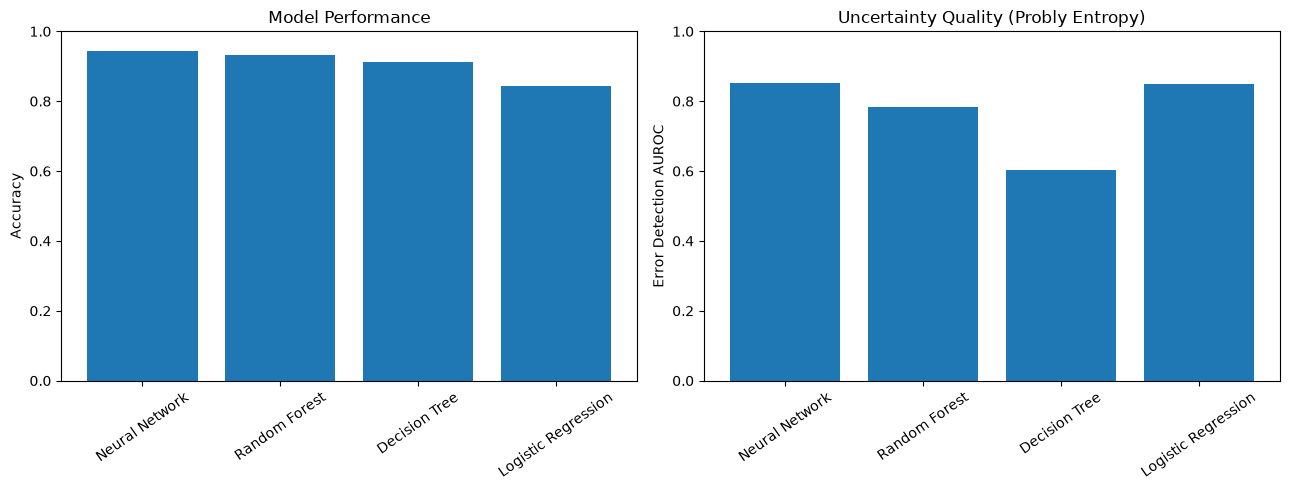

In [47]:
plot_df = results_df.sort_values("Accuracy", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy
axes[0].bar(plot_df["Model"], plot_df["Accuracy"])

axes[0].set_title("Model Performance")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=35)

# Uncertainty Quality
axes[1].bar(plot_df["Model"], plot_df["Error Detection AUROC"])

axes[1].set_title("Uncertainty Quality (Probly Entropy)")
axes[1].set_ylabel("Error Detection AUROC")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

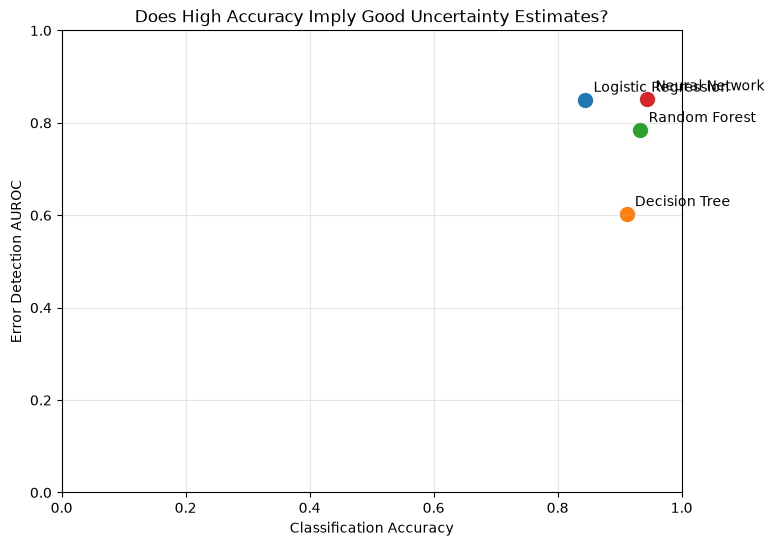

In [48]:
plt.figure(figsize=(8, 6))

for _, row in results_df.iterrows():
    plt.scatter(row["Accuracy"], row["Error Detection AUROC"], s=100)

    plt.annotate(
        row["Model"], (row["Accuracy"], row["Error Detection AUROC"]), xytext=(6, 6), textcoords="offset points"
    )

plt.xlabel("Classification Accuracy")
plt.ylabel("Error Detection AUROC")
plt.title("Does High Accuracy Imply Good Uncertainty Estimates?")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.show()

Bestätigt Hypothese 2: hohe Accuracy garantiert nicht direkt gute Unsciherheitsqualität

- Random Forest & Decision Tree: Hohe Accuracy und schlechtere Fehlererkennung
- Logistic Regression: Niedrigste Accuracy, aber fast so gute Fehlererkennung wie das Neural Network 